In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()

## attention-map

**Figure 3(a): Soft alignment found by RNNsearch-50 between an English source sentence and its generated French translation.** Each row shows the attention weights α_ij over the source words (columns) when generating target word i, from 0 (white) to 1 (dark blue). The alignment is mostly monotonic, but the model reverses the adjective–noun order: [zone] attends to [Area] (0.71), jumping over [European] and [Economic], then steps back one word at a time to [économique] → [Economic] (0.76) and [européenne] → [European] (0.97).

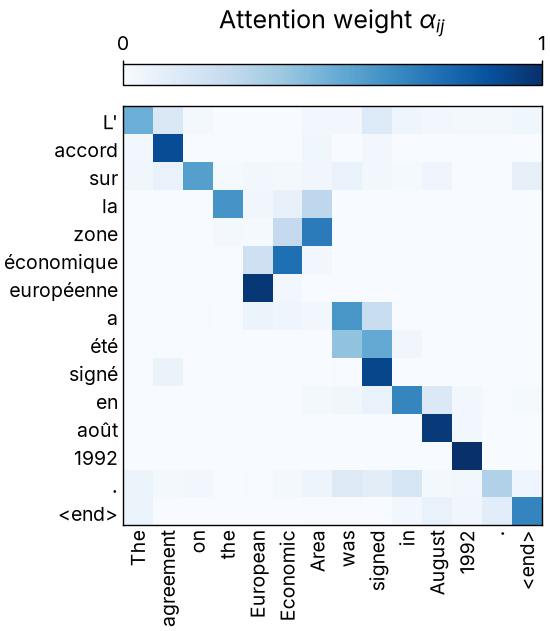

In [2]:
with open("../attention-map.json") as f:
    data = json.load(f)
weights = np.array(data["weights"])

fig, ax = plt.subplots(figsize=(2.75, 2.75))
im = ax.imshow(weights, aspect="auto", vmin=0, vmax=1)
# 90° rather than 45°: at half text width, 14 tokens overlap when turned 45°
ax.set_xticks(range(len(data["source_tokens"])), labels=data["source_tokens"], rotation=90)
ax.set_yticks(range(len(data["target_tokens"])), labels=data["target_tokens"])
ax.tick_params(length=0)
ax.grid(False)
# on top so the tokens get the full width; end ticks only, so the label clears them
fig.colorbar(im, ax=ax, location="top", ticks=[0, 1], label=r"Attention weight $\alpha_{ij}$")

fit_height(fig, ax, aspect=1.0)
fig.savefig("attention-map.pdf")
fig.savefig("attention-map.png")
plt.show()